# 05 - Channel models and SNR bookkeeping
**Objective.** Implement AWGN and Rayleigh block fading, verify their statistics, and state exactly how $\text{SNR}$, $E_s/N_0$, $E_b/N_0$, modulation order and code rate relate.

## SNR definitions (used everywhere in this project)
* **SNR $=E_s/N_0$**: received energy per *channel symbol* over the *complex* noise variance $N_0$ (this is the assignment's $\gamma=p\,g/(N_0BF)$ for one RB). With $E_s=1$: $n\sim\mathcal{CN}(0,N_0)$, $N_0=1/\text{SNR}$, i.e. $N_0/2$ per real dimension.
* $E_b/N_0 = \dfrac{E_s/N_0}{m\,R}$ with $m$ = bits/symbol and $R$ = code rate (info bits per coded bit). In dB: $E_b/N_0 = E_s/N_0 - 10\log_{10}(mR)$.
* Uncoded BPSK: $mR=1\Rightarrow E_s/N_0=E_b/N_0$. Uncoded QPSK: $mR=2$, so at equal $E_s/N_0$ QPSK has 3 dB lower $E_b/N_0$ (same BER-vs-$E_b/N_0$ curve as BPSK).
* **Rayleigh block fading**: $y = h x + n$, $h\sim\mathcal{CN}(0,1)$ constant over one resource block ($84$ symbols = 12 subcarriers x 7 OFDM symbols) and **independent between RBs**; $E|h|^2=1$ so SNR is the *average*, the instantaneous SNR of an RB is $|h|^2\,\text{SNR}$. A sentence of ~350-1000 symbols spans several RBs. Perfect CSI at the receiver is assumed.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional import channel as ch
from task1_conventional.communication_system import MCS_TABLE
rng = np.random.default_rng(2)

## 1. AWGN: noise variance check

In [3]:
x = np.ones(1_000_000, dtype=complex)
rows = []
for snr in (0, 5, 10, 20):
    y, n0 = ch.awgn(x, snr, rng); n = y - x
    rows.append(dict(snr_dB=snr, N0_target=1 / 10 ** (snr / 10), var_complex=np.mean(abs(n) ** 2), var_real=np.var(n.real) * 2, var_imag=np.var(n.imag) * 2))
display(pd.DataFrame(rows))

,snr_dB,N0_target,var_complex,var_real,var_imag
0,0,1.000000,0.999652,0.999933,0.999370
1,5,0.316228,0.316236,0.316109,0.316362
2,10,0.100000,0.100248,0.100287,0.100209
3,20,0.010000,0.009989,0.009975,0.010003


## 2. Rayleigh fading statistics

E|h|^2 = 0.9989 (target 1) | E|h| = 0.8855 (Rayleigh: sqrt(pi)/2 = 0.8862)


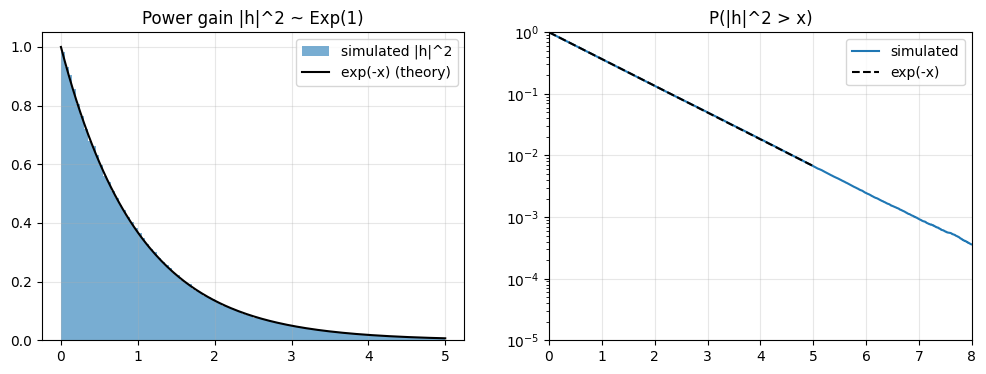

P(deep fade |h|^2 < 0.01) = 0.0100 (theory 1-exp(-0.01) = 0.0100)


In [4]:
h = ch.rayleigh_gains(500_000, rng); g = abs(h) ** 2
print("E|h|^2 = %.4f (target 1) | E|h| = %.4f (Rayleigh: sqrt(pi)/2 = %.4f)" % (g.mean(), abs(h).mean(), np.sqrt(np.pi) / 2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(g, bins=100, range=(0, 5), density=True, alpha=0.6, label="simulated |h|^2"); xs = np.linspace(0, 5, 200)
ax[0].plot(xs, np.exp(-xs), "k", label="exp(-x) (theory)"); ax[0].set_title("Power gain |h|^2 ~ Exp(1)"); ax[0].legend()
ax[1].semilogy(np.sort(g), 1 - np.arange(1, len(g) + 1) / len(g), label="simulated"); ax[1].semilogy(xs, np.exp(-xs), "k--", label="exp(-x)")
ax[1].set_xlim(0, 8); ax[1].set_ylim(1e-5, 1); ax[1].set_title("P(|h|^2 > x)"); ax[1].legend(); plt.show()
print("P(deep fade |h|^2 < 0.01) = %.4f (theory 1-exp(-0.01) = %.4f)" % ((g < 0.01).mean(), 1 - np.exp(-0.01)))

## 3. Block structure: independent fading per resource block

frames (symbols): [400, 350, 700] -> resource blocks: 19


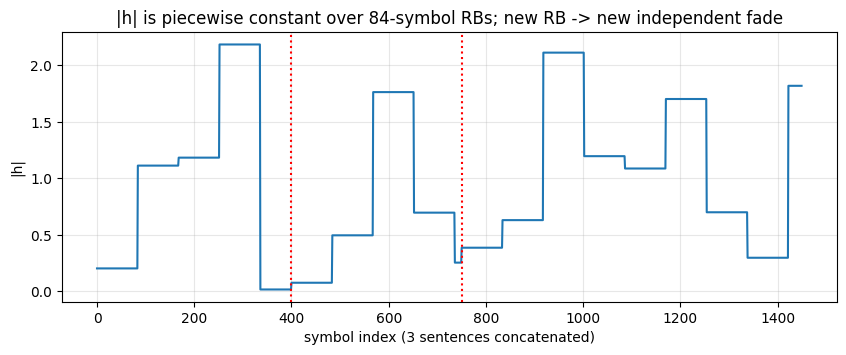

In [5]:
n_sym = [400, 350, 700]; ids, nblk = ch.block_ids(n_sym, 84)
x = np.ones(len(ids), dtype=complex); y, hs, n0 = ch.rayleigh_block_fading(x, 20.0, ids, nblk, rng)
print("frames (symbols):", n_sym, "-> resource blocks:", nblk)
fig, ax = plt.subplots(figsize=(10, 3.5)); ax.plot(abs(hs)); ax.set_xlabel("symbol index (3 sentences concatenated)"); ax.set_ylabel("|h|")
ax.set_title("|h| is piecewise constant over 84-symbol RBs; new RB -> new independent fade")
for b in np.cumsum(n_sym)[:-1]: ax.axvline(b, color="r", ls=":")
plt.show()

## 4. $E_s/N_0$ vs $E_b/N_0$ for the six MCSs

In [6]:
rows = []
for m in MCS_TABLE:
    for es in (5, 10, 20):
        rows.append(dict(MCS=m.name, bits_per_symbol=m.bps, code_rate=str(m.code_rate), mR=m.efficiency, EsN0_dB=es, EbN0_dB=round(float(ch.esn0_to_ebn0_db(es, m.bps, float(m.code_rate))), 2)))
t = pd.DataFrame(rows); display(t.pivot(index="MCS", columns="EsN0_dB", values="EbN0_dB"))
t.to_csv(TAB / "esn0_ebn0_conversion.csv", index=False)

EsN0_dB,5,10,20
MCS,,,
MCS1: QPSK 1/2,5.00,10.00,20.00
MCS2: QPSK 3/4,3.24,8.24,18.24
MCS3: 16QAM 1/2,1.99,6.99,16.99
MCS4: 16QAM 3/4,0.23,5.23,15.23
MCS5: 64QAM 2/3,-1.02,3.98,13.98
MCS6: 64QAM 3/4,-1.53,3.47,13.47


**Reading it:** at the same $E_s/N_0$ a high-order, high-rate MCS has a *much lower* $E_b/N_0$ (each bit gets less energy). All plots in this project use $E_s/N_0$ (the assignment's per-RB SNR $\gamma$) on the x-axis; the $E_b/N_0$ equivalent is stored in every CSV (`ebn0_db`).

## 5. Uncoded BPSK over Rayleigh fading vs closed form (validation of fading + ZF)

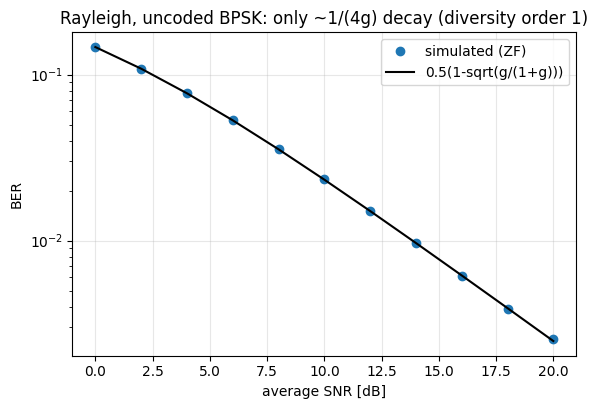

max relative error vs theory: 0.026


In [7]:
from task1_conventional.equalizer import zf_equalize
from task1_conventional.modulation import Modem
bpsk = Modem("BPSK"); snr = np.arange(0, 21, 2.0); sim = []
for s in snr:
    tx = rng.integers(0, 2, 2_000_000); x = bpsk.modulate(tx)
    y, hh, _ = ch.rayleigh_block_fading(x, s, np.arange(len(x)), len(x), rng); xh, _ = zf_equalize(y, hh)
    sim.append(np.mean(bpsk.demodulate_hard(xh) != tx))
g = 10 ** (snr / 10); th = 0.5 * (1 - np.sqrt(g / (1 + g)))
fig, ax = plt.subplots(figsize=(6.5, 4.2)); ax.semilogy(snr, sim, "o", label="simulated (ZF)"); ax.semilogy(snr, th, "k-", label="0.5(1-sqrt(g/(1+g)))")
ax.set_xlabel("average SNR [dB]"); ax.set_ylabel("BER"); ax.legend(); ax.set_title("Rayleigh, uncoded BPSK: only ~1/(4g) decay (diversity order 1)"); plt.show()
print("max relative error vs theory: %.3f" % np.max(abs(np.array(sim) / th - 1)))